# Ejercicios ensembling
En este ejercicio vas a realizar prediciones sobre un dataset de ciudadanos indios diabéticos. Se trata de un problema de clasificación en el que intentaremos predecir 1 (diabético) 0 (no diabético).

### 1. Carga las librerias que consideres comunes al notebook

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score

### 2. Lee los datos de [esta direccion](https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv)
Los nombres de columnas son:
```Python
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
```

In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

df = pd.read_csv(url, names=['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class'])
df.head()

,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    768 non-null    int64  
 2   pres    768 non-null    int64  
 3   skin    768 non-null    int64  
 4   test    768 non-null    int64  
 5   mass    768 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
 8   class   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()

,preg,plas,pres,skin,test,mass,pedi,age,class
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


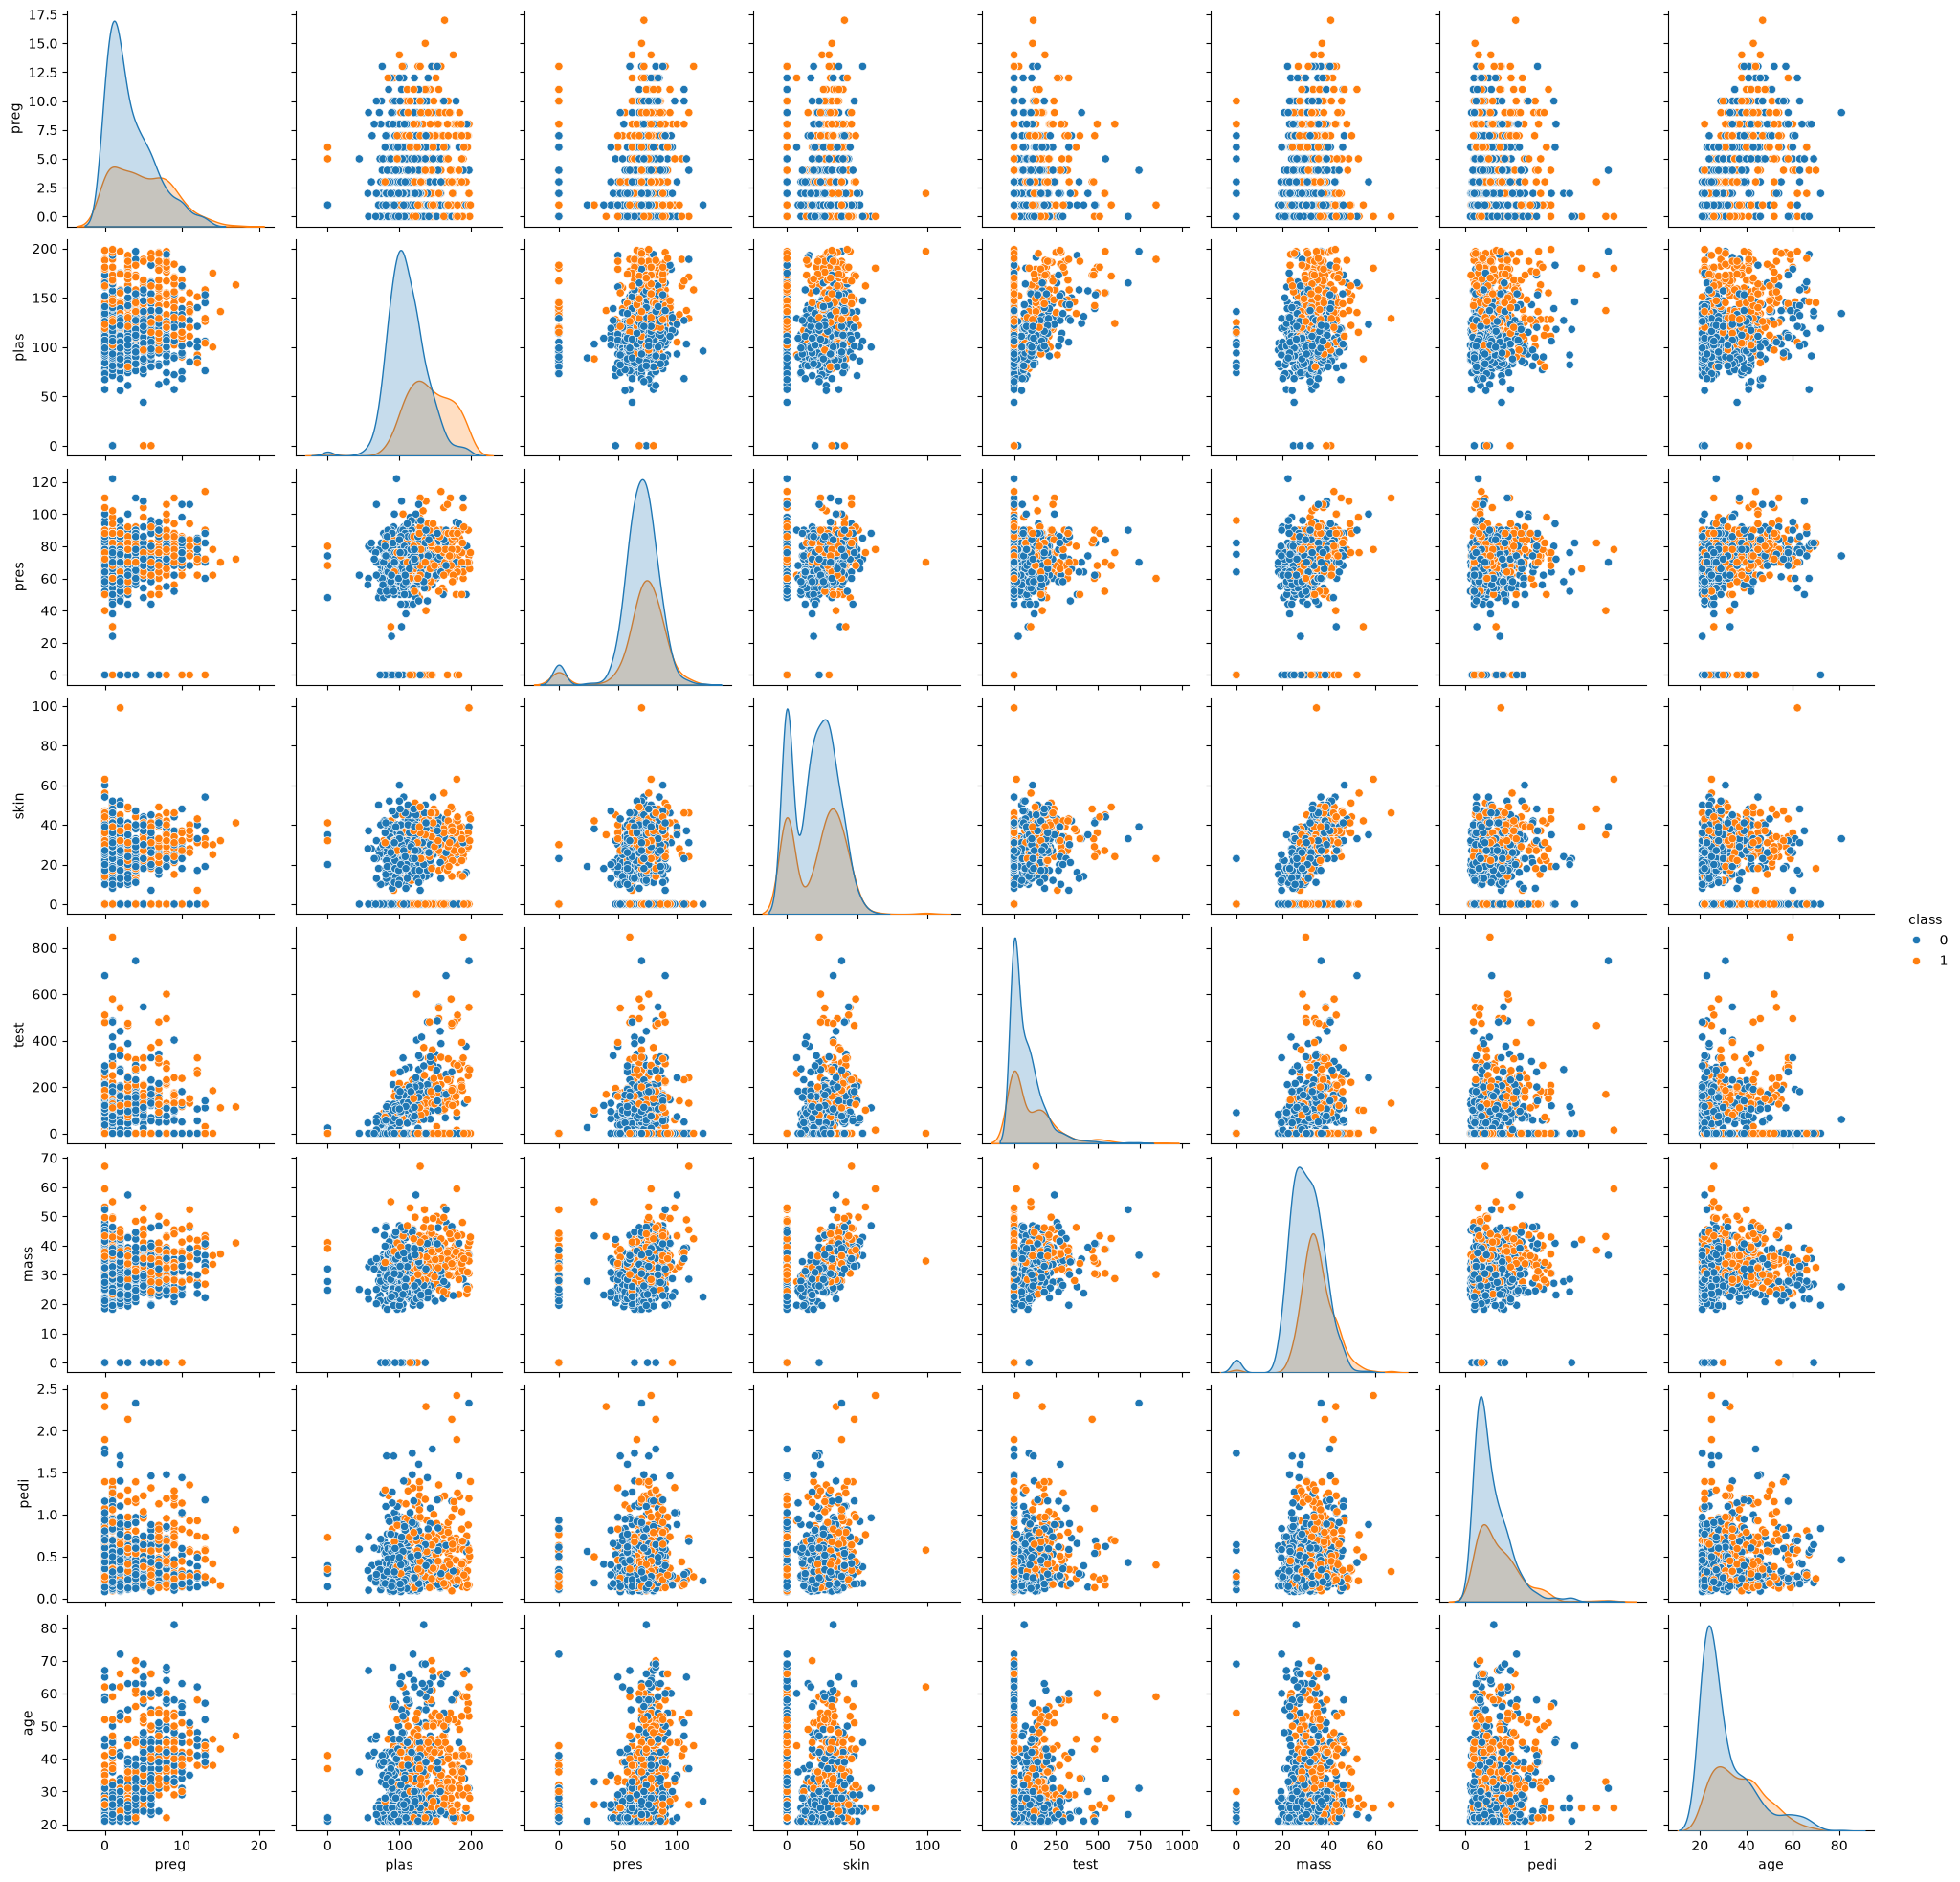

In [5]:
sns.pairplot(df, hue="class")

<Axes: >

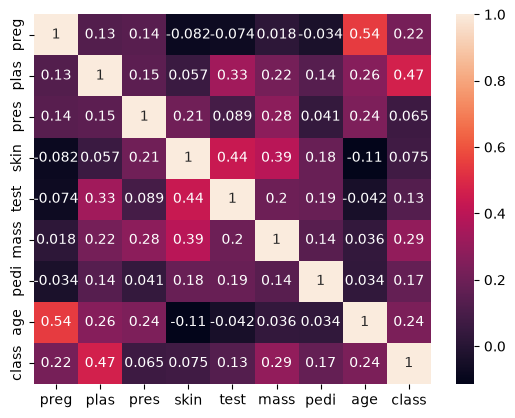

In [6]:
sns.heatmap(df.corr(), annot=True)

In [7]:
df['class'].value_counts(normalize=True)

class
0    0.651042
1    0.348958
Name: proportion, dtype: float64

### 3. Bagging
Para este apartado tendrás que crear un ensemble utilizando la técnica de bagging ([BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)), mediante la cual combinarás 100 [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html). Recuerda utilizar también [cross validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html) con 10 kfolds.

**Para este apartado y siguientes, no hace falta que dividas en train/test**, por hacerlo más sencillo. Simplemente divide tus datos en features y target.

Establece una semilla

In [8]:
X = df.drop(columns=['class'])
y = df['class']

seed = 42

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import KFold

In [10]:
dtc = DecisionTreeClassifier(max_depth=5)
bc = BaggingClassifier(estimator=dtc, n_estimators=100, random_state=seed)
kf = KFold(10)

In [11]:
for i, (train_index, test_index) in enumerate(kf.split(X)):
    print(f"Fold {i}:")
    # print(f"Train: index={train_index.min()}")
    print(f"Test: index={test_index.min()}")
    print(f"Test: index={test_index.max()}")

Fold 0:
Test: index=0
Test: index=76
Fold 1:
Test: index=77
Test: index=153
Fold 2:
Test: index=154
Test: index=230
Fold 3:
Test: index=231
Test: index=307
Fold 4:
Test: index=308
Test: index=384
Fold 5:
Test: index=385
Test: index=461
Fold 6:
Test: index=462
Test: index=538
Fold 7:
Test: index=539
Test: index=615
Fold 8:
Test: index=616
Test: index=691
Fold 9:
Test: index=692
Test: index=767


In [12]:
bc_cv = cross_val_score(bc, X, y, cv=kf, scoring="accuracy")
print(bc_cv)
print(bc_cv.mean())
print(bc_cv.std())

[0.7012987  0.81818182 0.7012987  0.64935065 0.77922078 0.85714286
 0.83116883 0.85714286 0.72368421 0.77631579]
0.7694805194805194
0.06893057161455383


### 4. Random Forest
En este caso entrena un [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) con 100 árboles y un `max_features` de 3. También con validación cruzada

In [13]:
from sklearn.ensemble import RandomForestClassifier

In [14]:
rfc = RandomForestClassifier(n_estimators=100, max_features=3, max_depth=5, random_state=seed)
rfc_cv = cross_val_score(rfc, X, y, cv=kf, scoring="accuracy")
print(rfc_cv)
print(rfc_cv.mean())
print(rfc_cv.std())

[0.71428571 0.83116883 0.74025974 0.64935065 0.75324675 0.81818182
 0.81818182 0.87012987 0.69736842 0.78947368]
0.7681647300068353
0.06546524440800212


### 5. AdaBoost
Implementa un [AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html) con 30 árboles.

In [15]:
from sklearn.ensemble import AdaBoostClassifier

In [16]:
abc = AdaBoostClassifier(n_estimators=30, random_state=seed)
abc_cv = cross_val_score(abc, X, y, cv=kf, scoring="accuracy")
print(abc_cv)
print(abc_cv.mean())
print(abc_cv.std())

[0.68831169 0.84415584 0.75324675 0.66233766 0.76623377 0.80519481
 0.77922078 0.83116883 0.72368421 0.80263158]
0.7656185919343814
0.056693414216223405


### 6. GradientBoosting
Implementa un [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) con 100 estimadores

In [17]:
from sklearn.ensemble import GradientBoostingClassifier

In [18]:
gbc = GradientBoostingClassifier(n_estimators=100, random_state=seed)
gbc_cv = cross_val_score(gbc, X, y, cv=kf, scoring="accuracy")
print(gbc_cv)
print(gbc_cv.mean())
print(gbc_cv.std())

[0.72727273 0.83116883 0.74025974 0.63636364 0.79220779 0.79220779
 0.80519481 0.83116883 0.71052632 0.78947368]
0.7655844155844156
0.058308188445863815


### 7. XGBoost
Para este apartado utiliza un [XGBoostClassifier](https://docs.getml.com/latest/api/getml.predictors.XGBoostClassifier.html) con 100 estimadores. XGBoost no forma parte de la suite de modelos de sklearn, por lo que tendrás que instalarlo con pip install

In [19]:
from xgboost import XGBClassifier

xgbc = XGBClassifier(n_estimators = 100, random_state=seed)
xgbc_cv = cross_val_score(xgbc, X, y, cv=kf, scoring="accuracy")
print(xgbc_cv)
print(xgbc_cv.mean())
print(xgbc_cv.std())

[0.7012987  0.76623377 0.72727273 0.66233766 0.75324675 0.74025974
 0.77922078 0.76623377 0.69736842 0.75      ]
0.7343472317156527
0.03518431576012921


### 8. Primeros resultados
Crea un dataframe con los resultados y sus algoritmos, ordenándolos de mayor a menor

In [20]:
results_cv = pd.DataFrame({"cv_mean_acc": [bc_cv.mean(),
                                           rfc_cv.mean(),
                                           abc_cv.mean(),
                                           gbc_cv.mean(),
                                           xgbc_cv.mean()]}, index=["Bag", "RF", "AB", "GB", "XGB"])
results_cv

,cv_mean_acc
Bag,0.769481
RF,0.768165
AB,0.765619
GB,0.765584
XGB,0.734347


### 9. Hiperparametrización
Vuelve a entrenar los modelos de nuevo, pero esta vez dividiendo el conjunto de datos en train/test y utilizando un gridsearch para encontrar los mejores hiperparámetros.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(614, 8)
(154, 8)
(614,)
(154,)


In [22]:
# RandomForestClassifier()

In [23]:
parameters = {
    "n_estimators": [20,50,100],
    "max_depth": np.arange(3,8),
    "max_leaf_nodes": [10,20,30]
}

3 * 5 * 3 * 10

450

In [24]:
rf_gs = GridSearchCV(RandomForestClassifier(random_state=seed), parameters, cv=kf, scoring="roc_auc", verbose=2)
rf_gs.fit(X_train, y_train)

Fitting 10 folds for each of 45 candidates, totalling 450 fits
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=20; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n_estimators=50; total time=   0.0s
[CV] END ....max_depth=3, max_leaf_nodes=10, n

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([3, 4, 5, 6, 7]), 'max_leaf_nodes': [10, 20, ...], 'n_estimators': [20, 50, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split...shuffle=False)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_g

In [25]:
print(rf_gs.best_estimator_)
print(rf_gs.best_params_)
print(rf_gs.best_score_)

RandomForestClassifier(max_depth=np.int64(4), max_leaf_nodes=20,
                       random_state=42)
{'max_depth': np.int64(4), 'max_leaf_nodes': 20, 'n_estimators': 100}
0.8395777927787205


In [26]:
h_rf = rf_gs.best_estimator_
h_rf.fit(X_train, y_train)

y_pred = h_rf.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(precision_score(y_test, y_pred))
print(roc_auc_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.7662337662337663
0.6
0.7021276595744681
0.7292929292929293
[[85 14]
 [22 33]]


In [27]:
hrf_cv = cross_val_score(h_rf, X, y, cv=kf, scoring="accuracy")
print(hrf_cv)
print(hrf_cv.mean())
print(hrf_cv.std())

[0.7012987  0.81818182 0.71428571 0.63636364 0.75324675 0.81818182
 0.80519481 0.85714286 0.72368421 0.78947368]
0.7617053998632948
0.06424577723553478


In [28]:
# GradientBoostingClassifier()

In [29]:
parameters = {
    "n_estimators": [20,50,100],
    "max_depth": np.arange(3,8),
    "learning_rate": [0.1,1,5]
}

3 * 5 * 3 * 10

450

In [30]:
gb_gs = GridSearchCV(GradientBoostingClassifier(random_state=seed), parameters, cv=kf, scoring="accuracy", verbose=2)
gb_gs.fit(X_train, y_train)

Fitting 10 folds for each of 45 candidates, totalling 450 fits
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=20; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n_estimators=50; total time=   0.0s
[CV] END ....learning_rate=0.1, max_depth=3, n

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1, 1, ...], 'max_depth': array([3, 4, 5, 6, 7]), 'n_estimators': [20, 50, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split...shuffle=False)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_g

In [31]:
print(gb_gs.best_estimator_)
print(gb_gs.best_params_)
print(gb_gs.best_score_)

GradientBoostingClassifier(max_depth=np.int64(3), random_state=42)
{'learning_rate': 0.1, 'max_depth': np.int64(3), 'n_estimators': 100}
0.7833157059756741


In [32]:
h_gb = gb_gs.best_estimator_
h_gb.fit(X_train, y_train)

y_pred = h_gb.predict(X_test)

print(accuracy_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(precision_score(y_test, y_pred))
print(roc_auc_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.7467532467532467
0.6727272727272727
0.6379310344827587
0.7303030303030302
[[78 21]
 [18 37]]


In [33]:
hgb_cv = cross_val_score(h_gb, X, y, cv=kf, scoring="accuracy")
print(hgb_cv)
print(hgb_cv.mean())
print(hgb_cv.std())

[0.72727273 0.83116883 0.74025974 0.63636364 0.79220779 0.79220779
 0.80519481 0.83116883 0.71052632 0.78947368]
0.7655844155844156
0.058308188445863815


### 10. Conclusiones finales

Escogemos el modelo que mejor generalice, es decir, el que tenga mejor métrica ante test (RF hiperparametrizado)

In [34]:
import pickle

In [35]:
with open("modelo_final.pkl", "wb") as f:
    pickle.dump(h_rf, f)

In [36]:
with open("modelo_final.pkl", "rb") as f:
    modelo_importado = pickle.load(f)

In [37]:
modelo_importado

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(4)
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bo

In [38]:
modelo_importado.predict([[10,10,10,10,10,10,10,10]])

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([0])

In [39]:
modelo_importado.feature_importances_

array([0.06320461, 0.38327513, 0.04084055, 0.03675811, 0.06470324,
       0.17254605, 0.06996251, 0.1687098 ])